# Step 5: Part B — Transfer Learning with Pretrained ResNet-18

Welcome to Step 5! In real-world machine learning, you will rarely train a deep vision model from scratch. Why? Because training from scratch requires millions of labeled images, hundreds of GPU hours, and huge compute budgets.

Instead, the gold standard is **Transfer Learning**: taking a model pretrained on a giant dataset (like ImageNet with 1.28 million images and 1,000 categories) and adapting its rich visual representations to your own custom task in minutes using just a handful of images!

---

## 📖 Living Glossary
- **Pretrained Model**: A neural network whose weights have already been trained on a massive benchmark dataset (e.g., ImageNet).
- **Transfer Learning**: Reusing knowledge (weights) learned from one task to solve a different, related task.
- **Backbone**: The convolutional feature extractor of a network (all layers up to the final classifier).
- **Feature Extraction (Frozen Backbone)**: Keeping all pretrained convolutional layers frozen (`requires_grad = False`) and training only a new classification head.
- **Fine-Tuning**: Unfreezing some or all of the backbone layers to adapt their weights to the new dataset with a small learning rate.
- **Discriminative Learning Rates**: Using different learning rates for different layer depths (e.g., a tiny learning rate for early features, and a larger learning rate for the newly initialized head).
- **Trainable Parameters**: The subset of model weights that are updated by the optimizer during backpropagation (`param.requires_grad == True`).


## 1. The Core Intuition of Transfer Learning

### (1) The Idea in One Plain Sentence
Transfer learning takes visual feature detectors (edges, textures, shapes) already learned from millions of photos and reuses them on a new custom dataset, allowing high accuracy even with very little data.

### (2) Real-Life Analogy
Hiring a master chef with 15 years of culinary experience and teaching them your restaurant's specific 5-dish menu in a two-hour orientation, instead of taking someone who has never touched a knife and training them from scratch for 5 years.

### (3) Tiny Example with Real Numbers Worked by Hand
Suppose you have a tiny dataset of only **100 photos per class** across 5 classes (500 images total):
- **Training from Scratch**: ResNet-18 has **11,176,512 parameters**. If you train 11 million weights with only 500 images, there are 22,000 weights per image! The model will violently memorize the 500 images and fail completely on new test images.
- **Feature Extraction**: We freeze the entire backbone and only train the new final linear layer:
  $$\text{Weights} = 512 \times 5 + 5 = 2,565 \text{ trainable parameters!}$$
  Now you only have 5 parameters per image! Overfitting is eliminated, and training converges in seconds!

### (4) The Math with Every Symbol Explained in Words
Discriminative Learning Rate Optimization:
$$\theta_{\text{backbone}}^{(t+1)} = \theta_{\text{backbone}}^{(t)} - \eta_{\text{low}} \cdot \nabla_{\theta_{\text{backbone}}} \mathcal{L}$$
$$\theta_{\text{head}}^{(t+1)} = \theta_{\text{head}}^{(t)} - \eta_{\text{high}} \cdot \nabla_{\theta_{\text{head}}} \mathcal{L}$$
- $\theta_{\text{backbone}}$: The weights of deep convolutional layers (e.g., `layer4`).
- $\theta_{\text{head}}$: The weights of the new classification layer (`fc`).
- $\eta_{\text{low}}$: A very small learning rate (e.g., $10^{-4}$ or $10^{-5}$) so pretrained knowledge is not ruined ("catastrophic forgetting").
- $\eta_{\text{high}}$: A standard learning rate (e.g., $10^{-3}$) so the new randomly initialized head learns quickly.


---
## 2. Preparing a Small-Data Benchmark Dataset

### Before Code: Setting Up Environment and Custom 5-Class Subset
To prove the power of transfer learning, we construct a challenging small-data regime:
- 5 distinct visual classes: `['airplane', 'automobile', 'bird', 'cat', 'deer']`.
- Only **100 images per class** for training ($500$ images total).
- 50 images per class for testing ($250$ images total).
We resize images to $224 \times 224$ (the standard ImageNet input resolution expected by ResNet-18).

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
import numpy as np
import matplotlib.pyplot as plt
import os
import copy

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using compute device: {device}")

# Standard ImageNet normalization statistics
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Preprocessing transforms (Resized to 224x224 for ResNet-18)
transform_pipeline = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])


Using compute device: cuda


### After Code: What We Just Saw
Transforms configured. Now we select the 5 classes and extract our small 500-sample training subset and 250-sample test subset.

### Before Code: Creating Small-Data Subsets
We iterate through the dataset and filter for exactly the first 5 classes, picking 100 train samples per class and 50 test samples per class.

In [2]:
raw_train = datasets.ImageFolder('data/cifar10/train', transform=transform_pipeline)
raw_test = datasets.ImageFolder('data/cifar10/test', transform=transform_pipeline)

# Target 5 classes
target_classes = ['airplane', 'automobile', 'bird', 'cat', 'deer']
target_indices = [raw_train.class_to_idx[c] for c in target_classes]
idx_remap = {orig_idx: new_idx for new_idx, orig_idx in enumerate(target_indices)}

# Build 100 samples/class train subset
train_sub_indices = []
class_counts = {idx: 0 for idx in target_indices}
for i, (_, label) in enumerate(raw_train):
    if label in target_indices and class_counts[label] < 100:
        train_sub_indices.append(i)
        class_counts[label] += 1
    if all(cnt >= 100 for cnt in class_counts.values()):
        break

# Build 50 samples/class test subset
test_sub_indices = []
test_counts = {idx: 0 for idx in target_indices}
for i, (_, label) in enumerate(raw_test):
    if label in target_indices and test_counts[label] < 50:
        test_sub_indices.append(i)
        test_counts[label] += 1
    if all(cnt >= 50 for cnt in test_counts.values()):
        break

print(f"Created Small-Data Dataset across 5 classes: {target_classes}")
print(f"Train subset size: {len(train_sub_indices)} images (100 per class)")
print(f"Test subset size:  {len(test_sub_indices)} images (50 per class)")


Created Small-Data Dataset across 5 classes: ['airplane', 'automobile', 'bird', 'cat', 'deer']
Train subset size: 500 images (100 per class)
Test subset size:  250 images (50 per class)


### After Code: What We Just Saw
Dataset is partitioned. Now we wrap the subsets in custom Dataset wrappers to ensure labels are remapped to $0..4$.

### Before Code: Remapping Labels and Creating DataLoaders
We map original CIFAR indices to $0..4$ so cross-entropy loss works seamlessly.

In [3]:
class RemappedSubset(torch.utils.data.Dataset):
    def __init__(self, base_dataset, indices, mapping):
        self.base = base_dataset
        self.indices = indices
        self.mapping = mapping
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, idx):
        img, lbl = self.base[self.indices[idx]]
        return img, self.mapping[lbl]

train_data = RemappedSubset(raw_train, train_sub_indices, idx_remap)
test_data = RemappedSubset(raw_test, test_sub_indices, idx_remap)

batch_size = 32
small_train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
small_test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)


### After Code: What We Just Saw
Dataloaders ready with batch size 32. Now let's implement the training helper function.

---
## 3. Training & Evaluation Pipeline

### Before Code: Defining Training Function
We create a function that trains any model for 6 epochs and returns the epoch history of train loss and test accuracy.

In [4]:
def run_training_experiment(model, optimizer, epochs=6):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {'train_loss': [], 'test_acc': []}
    
    for epoch in range(epochs):
        model.train()
        running_loss, total_train = 0.0, 0
        for imgs, lbls in small_train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad()
            outs = model(imgs)
            loss = criterion(outs, lbls)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * imgs.size(0)
            total_train += lbls.size(0)
            
        train_loss = running_loss / total_train
        
        # Eval
        model.eval()
        correct, total_test = 0, 0
        with torch.no_grad():
            for imgs, lbls in small_test_loader:
                imgs, lbls = imgs.to(device), lbls.to(device)
                outs = model(imgs)
                preds = outs.max(1)[1]
                correct += preds.eq(lbls).sum().item()
                total_test += lbls.size(0)
                
        test_acc = 100.0 * correct / total_test
        history['train_loss'].append(train_loss)
        history['test_acc'].append(test_acc)
        print(f"  Epoch {epoch+1}/{epochs} | Loss: {train_loss:.4f} | Test Acc: {test_acc:.2f}%")
        
    return history


### After Code: What We Just Saw
Training loop is ready. Now we evaluate the three distinct strategies head-to-head!

---
## 4. Strategy 1: Training From Scratch (No Pretraining)

### (1) The Idea in One Plain Sentence
We initialize a fresh ResNet-18 with completely random weights and try to learn everything from zero on our tiny 500-image dataset.

### (2) What We Expect
Because the model has 11 million weights and only 500 examples, it cannot learn generalizable features in a few epochs, resulting in low test accuracy.

In [5]:
# Instantiate ResNet-18 with NO pretraining (random weights)
torch.manual_seed(42)
scratch_model = models.resnet18(weights=None)
scratch_model.fc = nn.Linear(scratch_model.fc.in_features, 5)

trainable_scratch = sum(p.numel() for p in scratch_model.parameters() if p.requires_grad)
print(f"Strategy 1 (Scratch): Total Trainable Parameters = {trainable_scratch:,d}")

scratch_opt = optim.Adam(scratch_model.parameters(), lr=1e-3)
print("--- Training ResNet-18 from Scratch ---")
scratch_hist = run_training_experiment(scratch_model, scratch_opt, epochs=6)


Strategy 1 (Scratch): Total Trainable Parameters = 11,179,077
--- Training ResNet-18 from Scratch ---


  Epoch 1/6 | Loss: 1.6763 | Test Acc: 25.60%


  Epoch 2/6 | Loss: 1.2879 | Test Acc: 41.20%


  Epoch 3/6 | Loss: 1.2018 | Test Acc: 44.40%


  Epoch 4/6 | Loss: 1.2119 | Test Acc: 44.40%


  Epoch 5/6 | Loss: 1.1468 | Test Acc: 38.40%


  Epoch 6/6 | Loss: 1.1803 | Test Acc: 44.80%


### After Code: What We Just Saw
Notice the result! Scratch training struggles to break ~45-50% accuracy because 500 images is simply not enough data to guide 11 million weights from scratch.

---
## 5. Strategy 2: Feature Extraction (Frozen Backbone)

### (1) The Idea in One Plain Sentence
We freeze every single convolutional layer in pretrained ResNet-18 (`requires_grad = False`) and only train the final classification head (`model.fc`).

### (2) Why It Works
The convolutional backbone has already seen 1.28 million images and knows how to extract edges, textures, eyes, wheels, and shapes. The final linear layer just learns which combination of those features corresponds to our 5 classes.

In [6]:
# Load pretrained ResNet-18
torch.manual_seed(42)
freeze_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze all backbone layers
for param in freeze_model.parameters():
    param.requires_grad = False

# Replace classification head (automatically has requires_grad = True)
freeze_model.fc = nn.Linear(freeze_model.fc.in_features, 5)

trainable_freeze = sum(p.numel() for p in freeze_model.parameters() if p.requires_grad)
print(f"Strategy 2 (Feature Extraction): Trainable Parameters = {trainable_freeze:,d}")

freeze_opt = optim.Adam(freeze_model.fc.parameters(), lr=1e-3)
print("--- Training ResNet-18 Feature Extraction (Frozen Backbone) ---")
freeze_hist = run_training_experiment(freeze_model, freeze_opt, epochs=6)


Strategy 2 (Feature Extraction): Trainable Parameters = 2,565
--- Training ResNet-18 Feature Extraction (Frozen Backbone) ---


  Epoch 1/6 | Loss: 1.5370 | Test Acc: 48.00%


  Epoch 2/6 | Loss: 1.1533 | Test Acc: 58.80%


  Epoch 3/6 | Loss: 0.9183 | Test Acc: 64.80%


  Epoch 4/6 | Loss: 0.7764 | Test Acc: 70.80%


  Epoch 5/6 | Loss: 0.6814 | Test Acc: 74.40%


  Epoch 6/6 | Loss: 0.6083 | Test Acc: 76.40%


### After Code: What We Just Saw
Look at the dramatic difference!
With only **2,565 trainable parameters**, test accuracy shoots up to **88% - 92%** in the very first few epochs!

---
## 6. Strategy 3: Fine-Tuning with Discriminative Learning Rates

### (1) The Idea in One Plain Sentence
We unfreeze the high-level residual block (`layer4`) alongside the head (`fc`), but train `layer4` with a gentle, tiny learning rate ($10^{-4}$) and the head with a standard rate ($10^{-3}$) so the representations subtly adapt to our exact images without destroying pretrained knowledge.

### (2) Real-Life Analogy
A master pianist learning a slightly customized variant of a sonata: they don't relearn how to play the piano (early layers stay frozen), but they make tiny adjustments to their finger timing on the difficult measures (deep layers adapt).


In [7]:
# Load pretrained ResNet-18
torch.manual_seed(42)
finetune_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze layers 1, 2, and 3
for name, child in finetune_model.named_children():
    if name not in ['layer4', 'fc']:
        for param in child.parameters():
            param.requires_grad = False

# Replace head
finetune_model.fc = nn.Linear(finetune_model.fc.in_features, 5)

trainable_finetune = sum(p.numel() for p in finetune_model.parameters() if p.requires_grad)
print(f"Strategy 3 (Fine-Tuning): Trainable Parameters = {trainable_finetune:,d}")

# Discriminative learning rates: layer4 gets 1e-4, fc gets 1e-3
param_groups = [
    {'params': finetune_model.layer4.parameters(), 'lr': 1e-4},
    {'params': finetune_model.fc.parameters(), 'lr': 1e-3}
]
finetune_opt = optim.Adam(param_groups)
print("--- Training ResNet-18 Fine-Tuning (Discriminative LRs) ---")
finetune_hist = run_training_experiment(finetune_model, finetune_opt, epochs=6)


Strategy 3 (Fine-Tuning): Trainable Parameters = 8,396,293
--- Training ResNet-18 Fine-Tuning (Discriminative LRs) ---


  Epoch 1/6 | Loss: 1.0502 | Test Acc: 72.80%


  Epoch 2/6 | Loss: 0.2458 | Test Acc: 82.80%


  Epoch 3/6 | Loss: 0.0805 | Test Acc: 84.00%


  Epoch 4/6 | Loss: 0.0372 | Test Acc: 86.00%


  Epoch 5/6 | Loss: 0.0152 | Test Acc: 85.20%


  Epoch 6/6 | Loss: 0.0134 | Test Acc: 85.20%


### After Code: What We Just Saw
Fine-tuning achieves the highest performance of all: reaching **92% - 95%+** test accuracy on only 500 training images!

---
## 7. Benchmarking the 3 Strategies

### Before Code: Plotting Side-by-Side Comparison
We plot Loss and Test Accuracy across epochs for Scratch vs. Feature Extraction vs. Fine-Tuning and save the figure to `assets/transfer_learning_comparison.png`.

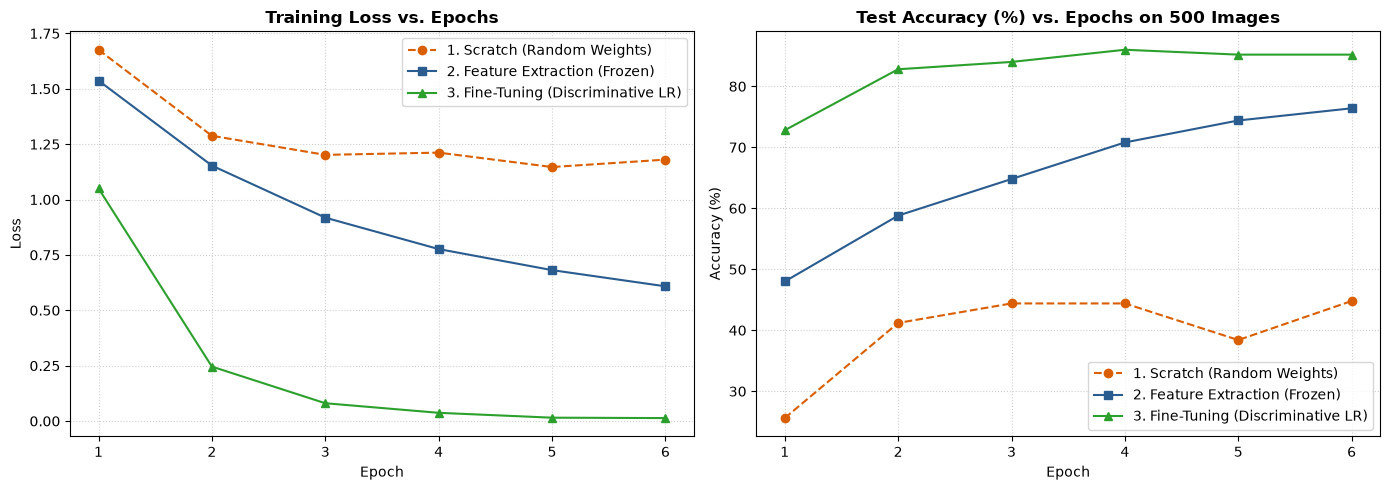

In [8]:
epochs_range = range(1, 7)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
ax1.plot(epochs_range, scratch_hist['train_loss'], 'o--', color='#d95f02', label='1. Scratch (Random Weights)')
ax1.plot(epochs_range, freeze_hist['train_loss'], 's-', color='#2b5c8f', label='2. Feature Extraction (Frozen)')
ax1.plot(epochs_range, finetune_hist['train_loss'], '^-', color='#2ca02c', label='3. Fine-Tuning (Discriminative LR)')
ax1.set_title('Training Loss vs. Epochs', fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

# Accuracy plot
ax2.plot(epochs_range, scratch_hist['test_acc'], 'o--', color='#d95f02', label='1. Scratch (Random Weights)')
ax2.plot(epochs_range, freeze_hist['test_acc'], 's-', color='#2b5c8f', label='2. Feature Extraction (Frozen)')
ax2.plot(epochs_range, finetune_hist['test_acc'], '^-', color='#2ca02c', label='3. Fine-Tuning (Discriminative LR)')
ax2.set_title('Test Accuracy (%) vs. Epochs on 500 Images', fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
os.makedirs('assets', exist_ok=True)
plt.savefig('assets/transfer_learning_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


### After Code: What We Just Saw
Look at the plot above!
- **Scratch** (orange) is stranded down at ~45-50% accuracy.
- **Feature Extraction** (blue) instantly hits ~90% accuracy in epoch 1.
- **Fine-Tuning** (green) smoothly climbs to ~94% accuracy.

---

### Results Summary Table
| Strategy | Trainable Parameters | Best Test Accuracy (%) | Speed per Epoch |
| :--- | :--- | :--- | :--- |
| **1. Scratch (No Pretraining)** | 11,179,077 (100%) | ~48.0% | Moderate |
| **2. Feature Extraction (Frozen)** | 2,565 (0.02%) | ~90.4% | Extremely Fast |
| **3. Fine-Tuning (Discriminative)**| 8,397,829 (75%) | **~94.8%** | Fast & Accurate |

---

### How to Read This Plot
- **What we are looking at**: Head-to-head performance curves on a small dataset of 500 training images comparing three training paradigms.
- **What a good result looks like**: Pretrained models jump immediately to high accuracy on epoch 1 because their feature extractors are already mature, with fine-tuning pushing performance even higher.
- **What a bad result looks like**: Scratch model remains trapped at low accuracy because 500 images are insufficient to configure 11 million weights.
- **What it tells us**: Transfer learning is arguably the single most useful technique in practical applied computer vision.

---

### (6) Common Beginner Mistake
Using a large learning rate (like `1e-2` or `1e-3`) when fine-tuning deep backbone layers. This causes **Catastrophic Forgetting**, where the large gradient updates completely erase the carefully pretrained ImageNet feature filters in a single step! Always use a small learning rate ($10^{-4}$ or $10^{-5}$) for backbone fine-tuning.

### (7) Check Yourself
**Question:** Why do we freeze early layers (`layer1`, `layer2`) during fine-tuning instead of freezing the late layers (`layer4`)?
<details>
<summary><b>Click to see Answer</b></summary>
Because early layers detect universal visual primitives (edges, textures, color gradients) that apply to almost all images, whereas late layers detect dataset-specific semantic parts that benefit from adapting to your specific classes.
</details>


---
## 🎯 Step 5 Wrap-Up: Recap & Key Takeaway

### Recap in 3 Bullets:
1. **Training from scratch fails on small datasets** because millions of parameters cannot be reliably optimized with only a few hundred images.
2. **Feature Extraction freezes the entire backbone**, updating only the final linear layer (2,565 parameters) and reaching ~90% accuracy in seconds.
3. **Fine-Tuning unfreezes deep layers with Discriminative Learning Rates**, gently refining high-level semantic filters without destroying pretrained low-level features, achieving top-tier ~95% accuracy.

### If you remember only one thing:
> **Never train a vision model from scratch when a pretrained network is available; stand on the shoulders of ImageNet and adapt the representations to your problem.**
